# Experimentación y Justificación de la Selección de Modelos por Nodo Homogéneo (Arquitectura QBAF + DF-QuAD)
### Reto AgroCebada FIRA 2026 | La Naturaleza Matemática de los Datos como Punto de Partida para la Búsqueda Algorítmica
---

**Equipo:** TecnoBuhos  
**Objetivo del Cuaderno:** Documentar paso a paso cómo **la naturaleza matemática y estadística intrínseca de los datos en cada Nodo Homogéneo ($G_{\text{Bio}}$, $G_{\text{Geo-Labranza}}$, $G_{\text{SWIR-Termo}}$, $G_{\text{Clima-PLS}}$, $G_{\text{Meseta-Modal}}$)** constituye el punto de partida para dirigir la búsqueda de algoritmos candidatos, y validar experimentalmente la elección final mediante **Validación Cruzada Out-Of-Fold ($K=3$)**, **tolerancia a ruido sintético ($20\%$)** e **invariancia física ante nubosidad ($20\%$)**.

---

## 1. ¿Por qué la Búsqueda de Modelos Debe Partir de la Naturaleza Matemática de los Datos?

En aprendizaje automático aplicado a ciencias agroecológicas y sensores remotos, ningún algoritmo es universalmente superior en todos los subespacios (*Teorema de No Free Lunch*). Antes de entrenar o buscar hiperparámetros, es indispensable diagnosticar **cuatro propiedades matemáticas fundamentales** de la matriz de diseño $\mathbf{X}_g \in \mathbb{R}^{N_g \times p_g}$ y del vector objetivo $\mathbf{y}_g \in \mathbb{R}^{N_g}$ en cada nodo:

1. **Geometría Funcional de la Respuesta (Particiones por Umbral vs. Continuidad Espacial):**
   * **Nodo 1 ($G_{\text{Bio}}$ — Hidalgo):** La fisiología vegetal frente al estrés hídrico (`s2_ndwi_mean`), absorción de clorofila en borde rojo (`s2_mra_mean`) y heladas (`bi_Tmin_anom25_04`) responde mediante **umbrales críticos no lineales** (puntos de quiebre biológicos). Esta naturaleza matemática guía la búsqueda hacia **ensambles de árboles de decisión (`GradientBoosting`, `RandomForest`, `ExtraTrees`)** capaces de particionar ortogonalmente el espacio por umbrales.
   * **Nodo 2 ($G_{\text{Geo-Labranza}}$ — Puebla):** Las variables topográficas (`elevacion_msnm`, `pendiente_grados`, `proxy_relieve_m`), coordenadas espaciales y labranza pre-siembra (`s2_sti_presow`) describen una **superficie espacial continua y suave**, lo que orienta la búsqueda hacia **métodos de Kernel en espacios de Hilbert (`SVR RBF` y Procesos Gaussianos `GPR`)**.
2. **Morfología Distribucional, Curtosis y Tasa de Valores Atípicos (*Outliers* IQR):**
   * **Nodo 3 ($G_{\text{SWIR-Termo}}$ — Puebla):** Las lecturas térmicas (`landsat_vi6t_std`) y ópticas finas en cuencas nubosas presentan **colas pesadas y valores atípicos extremos** por contaminación de bordes de nube. Los estimadores de pérdida cuadrática pura ($L_2$) amplifican cuadráticamente estos errores; por ello, la naturaleza leptocúrtica del dato dirige la búsqueda hacia **regresión M-robusta con pérdida híbrida $L_2/L_1$ (`HuberRegressor`)**.
3. **Condicionamiento Espectral y Multicolinealidad ($\kappa(\mathbf{X}) = \sigma_{\max}/\sigma_{\min}$):**
   * **Nodo 4 ($G_{\text{Clima-PLS}}$ — Puebla):** Las decenas de variables climáticas mensuales están fuertemente correlacionadas entre sí ($p \gg N$), produciendo una matriz mal condicionada ($\kappa(\mathbf{X}) \gg 30$). La naturaleza colineal del subespacio obliga a iniciar la búsqueda con **reducción de dimensionalidad supervisada (`PLSRegression k=2`)** que maximice la covarianza $\text{Cov}(\mathbf{X}w, \mathbf{y})^2$ antes de alimentar los regresores.
4. **Topología Continua vs. Discretizada de la Variable Objetivo ($Y$):**
   * **Nodo 5 ($G_{\text{Meseta-Modal}}$ — Tlaxcala):** El análisis de cuantización revela que los rendimientos reportados en Tlaxcala se agrupan casi en su totalidad en **escalones discretos múltiplos de $0.5\text{ t/ha}$** ($2.5, 3.0, 3.5\text{ t/ha}$). Forzar un regresor continuo estándar sobre una variable objetivo escalonada provoca sobreajuste severo; por tanto, la naturaleza discreta/ordinal del dato guía la búsqueda hacia **Clasificación Ordinal Probabilística (`SVC RBF`) ponderada con un Anclaje Modal ($3.0\text{ t/ha}$)** mediante la esperanza $\mathbb{E}[Y|X] = \sum P(Y = c_k | X) \cdot c_k$.

In [1]:
# 1.1 Configuración del entorno e integración de las fuentes de datos oficiales
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import kurtosis

from sklearn.model_selection import KFold
from sklearn.metrics import r2_score, mean_absolute_error, root_mean_squared_error
from sklearn.preprocessing import RobustScaler, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor, GradientBoostingRegressor
from sklearn.svm import SVR, SVC
from sklearn.linear_model import Ridge, HuberRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, ConstantKernel as C, WhiteKernel
from sklearn.cross_decomposition import PLSRegression
from sklearn.decomposition import PCA

SEED = 42
np.random.seed(SEED)
plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'

# Carga de tablas oficiales desde la carpeta data/
from pathlib import Path
BASE_DIR = Path.cwd().parent if Path.cwd().name.lower() in ['notebooks', 'notebook'] else Path.cwd()
DATA_DIR = BASE_DIR / 'data'

df_basico = pd.read_csv(DATA_DIR / 'Conjunto_datos_BASICO_AgroCebada2026.csv')
df_pro    = pd.read_csv(DATA_DIR / 'Conjunto_datos_PRO_AgroCebada.csv')
y_df      = pd.read_csv(DATA_DIR / 'ID_area_rendimiento_70_30_Reto_AgroCebada.csv')
shp       = gpd.read_file(DATA_DIR / 'shp/Parcelas_Reto_AGC_CONJUNTO.shp')
topo      = pd.read_csv(DATA_DIR / 'topografia_inegi_cem4_parcelas.csv')
p_coords  = pd.read_csv(DATA_DIR / 'parcelas_con_topografia.csv')
temp_df   = pd.read_csv(DATA_DIR / 'temperatura_chirts_era5_parcelas.csv')

for d in [df_basico, df_pro, y_df, topo, temp_df]:
    d['ID_POLIGONO'] = d['ID_POLIGONO'].astype(str).str.strip()
shp['ID_POLIGONO'] = shp['ID_POLIGON'].astype(str).str.strip()
p_coords['ID_POLIGONO'] = p_coords['ID_POLIGON'].astype(str).str.strip()
y_df['CONJUNTO'] = y_df['CONJUNTO'].astype(str).str.strip()
y_df['RENDIMIENTO'] = y_df['RENDIMIENTO_T_HA']

bounds_utm = shp.to_crs(epsg=32614).geometry.bounds
geo = shp[['ID_POLIGONO', 'Estado', 'Municipio', 'geometry']].copy()
geo['lat_centro'] = geo.geometry.centroid.y
geo['lon_centro'] = geo.geometry.centroid.x
geo['elongacion_bbox'] = (bounds_utm['maxx'] - bounds_utm['minx']) / (bounds_utm['maxy'] - bounds_utm['miny'] + 1e-6)
geo = geo.drop(columns='geometry').merge(
    topo[['ID_POLIGONO', 'elevacion_msnm', 'pendiente_grados']], on='ID_POLIGONO', how='left'
).merge(
    p_coords[['ID_POLIGONO', 'proxy_relieve_m']], on='ID_POLIGONO', how='left'
)

df_basico['mes'] = pd.to_datetime(df_basico['fecha_captura'], dayfirst=True).dt.month
df_pro['mes']    = pd.to_datetime(df_pro['fecha_captura'], dayfirst=True).dt.month

df_b = df_basico[df_basico['porcentaje_nubosidad'].fillna(100) <= 30.0]
df_p = df_pro[df_pro['porcentaje_nubosidad'].fillna(100) <= 30.0]

s2 = df_b[df_b['sensor'] == 'Sentinel-2']
s2_feats = s2.groupby('ID_POLIGONO').agg(
    s2_ndwi_mean=('ndwi_promedio', 'mean'), s2_ndwi_min=('ndwi_promedio', 'min'),
    s2_dswi2_mean=('dswi2_promedio', 'mean'), s2_fapar_mean=('fapar_promedio', 'mean'),
    s2_savi_mean=('savi_promedio', 'mean'), s2_mra_mean=('mra_promedio', 'mean'),
    s2_evi_intra_std=('evi_std', 'mean')
).reset_index()

s2_presow = s2[s2['mes'].isin([1, 2, 3, 4])].groupby('ID_POLIGONO').agg(
    s2_sti_presow=('sti_promedio', 'mean'), s2_ndti_presow=('ndti_promedio', 'mean')
).reset_index()

landsat_feats = df_b[df_b['sensor'] == 'Landsat'].groupby('ID_POLIGONO').agg(
    landsat_vi6t_max=('vi6t_promedio', 'max'), landsat_vi6t_std=('vi6t_promedio', 'std'),
    landsat_vi6t_mean=('vi6t_promedio', 'mean'), landsat_intra_vi6t_std=('vi6t_std', 'mean')
).reset_index()

planet_feats = df_p.groupby('ID_POLIGONO').agg(
    planet_lai_std=('lai_promedio', 'std'), planet_lai_mean=('lai_promedio', 'mean'),
    planet_ndvi_mean=('ndvi_promedio', 'mean'), planet_msavi_mean=('msavi_promedio', 'mean'),
    planet_intra_ndvi_std=('ndvi_std', 'mean')
).reset_index()

persistencia_m11 = df_p[df_p['mes'] == 11].groupby('ID_POLIGONO')['ndvi_promedio'].mean().reset_index().rename(
    columns={'ndvi_promedio': 'persistencia_verde_m11'}
)

data = y_df.merge(geo, on='ID_POLIGONO', how='left')
for tabla_sensor in [s2_feats, s2_presow, landsat_feats, planet_feats, persistencia_m11, temp_df]:
    data = data.merge(tabla_sensor, on='ID_POLIGONO', how='left')

data['persistencia_verde_m11'] = data['persistencia_verde_m11'].fillna(0)
data['estres_termohidrico'] = data['landsat_vi6t_max'] * data['s2_ndwi_min']
data['log_area'] = np.log1p(data['AREA_HA'])

train_df = data[data['CONJUNTO'] == 'ENTRENAMIENTO'].copy().reset_index(drop=True)

# Definición de los 5 Nodos Homogéneos de Variables
temp_hidalgo_cols = ['bi_Tmin_anom25_04', 'nn_vpd_vege_std', 'bi_canopy_air_diff', 'lp_Tmin_anom25_04', 's2_mra_mean']
feats_nodo1_hidalgo_bio = [
    'log_area', 'landsat_vi6t_max', 's2_ndwi_mean', 'planet_lai_std',
    'persistencia_verde_m11', 'estres_termohidrico', 'elevacion_msnm',
    'pendiente_grados', 's2_dswi2_mean'
] + temp_hidalgo_cols

extra_puebla_cols = ['bi_vpd_ndwi_stress', 'proxy_relieve_m', 's2_sti_presow']
feats_nodo2_puebla_geo  = ['lat_centro', 'lon_centro', 'log_area', 'pendiente_grados', 'elevacion_msnm', 's2_ndwi_min'] + extra_puebla_cols
feats_nodo3_puebla_swir = ['log_area', 'pendiente_grados', 'elevacion_msnm', 's2_ndwi_min', 's2_dswi2_mean', 'landsat_vi6t_std', 'planet_lai_std', 'planet_ndvi_mean'] + extra_puebla_cols

pls_pool_nodo4_puebla = [c for c in temp_df.columns if c.startswith('bi_')] + [
    's2_sti_presow', 's2_ndti_presow', 's2_fapar_mean', 's2_evi_intra_std',
    's2_savi_mean', 's2_mra_mean', 'proxy_relieve_m', 'sync_canopy_ratio_mean',
    'heat_stress_pv_2025', 'heat_stress_pv_2023', 'gdd_card_anom25', 'cold_repro_anom25',
    'dyn_tmin_llenado', 'dyn_dtr_llenado', 'planet_intra_ndvi_std'
]
feats_nodo5_tlaxcala = ['lat_centro', 'lon_centro', 'landsat_intra_vi6t_std', 'planet_msavi_mean', 'elongacion_bbox']

print("Subespacios de los 5 Nodos Homogéneos configurados correctamente.")

Subespacios de los 5 Nodos Homogéneos configurados correctamente.


## 2. Fase A: Diagnóstico Cuantitativo de la Naturaleza Matemática de cada Nodo (Punto de Partida)

Antes de iniciar la búsqueda de modelos, calculamos para cada uno de los 5 Nodos Homogéneos sus **invariantes estadísticos y matriciales** ($\kappa(\mathbf{X})$, tasa de valores atípicos $\text{IQR}$, curtosis máxima y porcentaje de discretización de $Y$), los cuales determinan qué familias matemáticas de modelos deben evaluarse en cada nodo:

In [2]:
# 2. FASE A: Diagnóstico Estadístico Intrínseco de cada Nodo Homogéneo (SVD Condition Number, IQR Outliers, Curtosis y Discretización)
nodos_config = [
    ('Nodo 1: G_Bio (Hidalgo)', 'Hidalgo', feats_nodo1_hidalgo_bio),
    ('Nodo 2: G_Geo-Labranza (Puebla)', 'Puebla', feats_nodo2_puebla_geo),
    ('Nodo 3: G_SWIR-Termo (Puebla)', 'Puebla', feats_nodo3_puebla_swir),
    ('Nodo 4: G_Clima-PLS (Puebla)', 'Puebla', pls_pool_nodo4_puebla),
    ('Nodo 5: G_Meseta-Modal (Tlaxcala)', 'Tlaxcala', feats_nodo5_tlaxcala)
]

diagnostico_nodos = []
for nombre_nodo, est, cols_n in nodos_config:
    sub = train_df[train_df['Estado'] == est].reset_index(drop=True)
    X_raw = SimpleImputer(strategy='median').fit_transform(sub[cols_n])
    X_std = StandardScaler().fit_transform(X_raw)
    
    # Valores singulares para número de condición espectral kappa(X)
    s_vals = np.linalg.svd(X_std, compute_uv=False)
    s_pos = s_vals[s_vals > 1e-6]
    kappa = float(s_pos[0] / s_pos[-1]) if len(s_pos) > 1 else 1.0
    
    # Tasa de outliers por criterio IQR y curtosis máxima
    q25, q75 = np.percentile(X_raw, 25, axis=0), np.percentile(X_raw, 75, axis=0)
    iqr = q75 - q25 + 1e-9
    outliers_pct = float(np.mean((X_raw < (q25 - 1.5 * iqr)) | (X_raw > (q75 + 1.5 * iqr))) * 100.0)
    kurt_max = float(np.nanmax(kurtosis(X_raw, axis=0, fisher=True)))
    
    # Fracción de cuantización en múltiplos de 0.5 t/ha
    y_st = sub['RENDIMIENTO'].values
    cuant_pct = float(np.mean(np.isclose(y_st * 2.0, np.round(y_st * 2.0), atol=1e-2)) * 100.0)
    
    diagnostico_nodos.append({
        'Nodo Homogéneo QBAF': nombre_nodo,
        'Estado': est,
        'N Parcelas': len(sub),
        'Dimensión (p)': len(cols_n),
        'Condición SVD κ(X)': round(kappa, 1),
        'Outliers IQR (%)': round(outliers_pct, 2),
        'Curtosis Máx': round(kurt_max, 2),
        'Target en Múltiplos 0.5 t/ha (%)': round(cuant_pct, 1)
    })

df_diagnostico_intrinsico = pd.DataFrame(diagnostico_nodos)
print("=" * 115)
print("FASE A: DIAGNÓSTICO ESTADÍSTICO INTRÍNSECO POR NODO HOMOGÉNEO (PRE-MODELADO)")
print("=" * 115)
display(df_diagnostico_intrinsico)

FASE A: DIAGNÓSTICO ESTADÍSTICO INTRÍNSECO POR NODO HOMOGÉNEO (PRE-MODELADO)


,Nodo Homogéneo QBAF,Estado,N Parcelas,Dimensión (p),Condición SVD κ(X),Outliers IQR (%),Curtosis Máx,Target en Múltiplos 0.5 t/ha (%)
0,Nodo 1: G_Bio (Hidalgo),Hidalgo,36,14,18.6,3.37,2.36,36.1
1,Nodo 2: G_Geo-Labranza (Puebla),Puebla,71,9,6.6,1.88,2.94,1.4
2,Nodo 3: G_SWIR-Termo (Puebla),Puebla,71,11,7.8,1.92,2.94,1.4
3,Nodo 4: G_Clima-PLS (Puebla),Puebla,71,299,118158430.5,0.22,3.76,1.4
4,Nodo 5: G_Meseta-Modal (Tlaxcala),Tlaxcala,31,5,1.7,1.29,4.06,100.0


In [3]:
# 3. FASE B: Torneo Experimental de Algoritmos por Nodo Homogéneo (CV K=3, Ruido Sintético 20% e Invariancia a Nubes 20%)
kf_torneo = KFold(n_splits=3, shuffle=True, random_state=SEED)

def aplicar_perturbacion_nubes_20pct(X_va_scaled, fold_seed):
    """Simula un 20% de escenas contaminadas por nubosidad y bordes térmicos en el espacio escalado."""
    rng_c = np.random.RandomState(fold_seed + 500)
    X_c = X_va_scaled.copy()
    n_cols = min(3, X_c.shape[1])
    mask_cloud = rng_c.rand(X_c.shape[0], n_cols) < 0.20
    X_c[:, :n_cols] = np.where(mask_cloud, X_c[:, :n_cols] - 2.2, X_c[:, :n_cols])
    return X_c

resultados_torneo_nodos = []

# --- TORNEO EN NODOS 1, 2 Y 3 ---
for nombre_nodo, est, cols_n in [
    ('Nodo 1: G_Bio (Hidalgo)', 'Hidalgo', feats_nodo1_hidalgo_bio),
    ('Nodo 2: G_Geo-Labranza (Puebla)', 'Puebla', feats_nodo2_puebla_geo),
    ('Nodo 3: G_SWIR-Termo (Puebla)', 'Puebla', feats_nodo3_puebla_swir)
]:
    sub = train_df[train_df['Estado'] == est].reset_index(drop=True)
    y_real = sub['RENDIMIENTO'].values
    
    candidatos = {
        'GradientBoosting': lambda s: GradientBoostingRegressor(n_estimators=80, max_depth=3, random_state=s),
        'RandomForest': lambda s: RandomForestRegressor(n_estimators=100, max_depth=5, random_state=s),
        'ExtraTrees': lambda s: ExtraTreesRegressor(n_estimators=130, max_depth=5, min_samples_split=3, random_state=s),
        'SVR (Kernel RBF)': lambda s: SVR(kernel='rbf', C=1.0, epsilon=0.15, gamma=0.1 if est=='Puebla' else 'scale'),
        'GPR (RBF + WhiteKernel)': lambda s: GaussianProcessRegressor(
            kernel=C(1.0, (1e-3, 1e3)) * RBF(length_scale=1.0, length_scale_bounds=(1e-2, 1e2)) + WhiteKernel(noise_level=0.1),
            n_restarts_optimizer=2, random_state=s, normalize_y=True
        ),
        'HuberRegressor (L2/L1)': lambda s: HuberRegressor(alpha=1.0, epsilon=1.2, max_iter=500),
        'Ridge (L2)': lambda s: Ridge(alpha=1.0, random_state=s),
        'Red Neuronal MLP (64-32)': lambda s: MLPRegressor(hidden_layer_sizes=(64, 32), max_iter=600, random_state=s)
    }
    
    for nom_alg, fn_alg in candidatos.items():
        oof_clean = np.zeros(len(sub))
        oof_noise = np.zeros(len(sub))
        oof_cloud = np.zeros(len(sub))
        
        for fold, (f_tr, f_va) in enumerate(kf_torneo.split(sub)):
            tr_f, va_f = sub.iloc[f_tr], sub.iloc[f_va]
            y_tr = tr_f['RENDIMIENTO'].values
            
            imp, sc = SimpleImputer(strategy='median'), RobustScaler()
            X_tr_base = sc.fit_transform(imp.fit_transform(tr_f[cols_n]))
            X_va_base = sc.transform(imp.transform(va_f[cols_n]))
            X_va_cloud = aplicar_perturbacion_nubes_20pct(X_va_base, SEED + fold)
            
            rng = np.random.RandomState(SEED + fold + 100)
            X_va_noise = X_va_base + rng.normal(0, 0.15, size=X_va_base.shape)
            
            if est == 'Hidalgo':
                m_m, m_c, g_m = tr_f.groupby('Municipio')['RENDIMIENTO'].mean().to_dict(), tr_f.groupby('Municipio')['RENDIMIENTO'].count().to_dict(), tr_f['RENDIMIENTO'].mean()
                p_fn = lambda m: (m_c.get(m, 0) * m_m.get(m, g_m) + 0.5 * g_m) / (m_c.get(m, 0) + 0.5)
                p_tr = tr_f['Municipio'].apply(p_fn).values.reshape(-1, 1)
                p_va = va_f['Municipio'].apply(p_fn).values.reshape(-1, 1)
                X_tr_base  = np.hstack([X_tr_base, p_tr])
                X_va_base  = np.hstack([X_va_base, p_va])
                X_va_noise = np.hstack([X_va_noise, p_va])
                X_va_cloud = np.hstack([X_va_cloud, p_va])
            
            mod = fn_alg(SEED + fold).fit(X_tr_base, y_tr)
            oof_clean[f_va] = np.clip(mod.predict(X_va_base), 1.50, 4.80)
            oof_noise[f_va] = np.clip(mod.predict(X_va_noise), 1.50, 4.80)
            oof_cloud[f_va] = np.clip(mod.predict(X_va_cloud), 1.50, 4.80)
            
        mae_c = float(mean_absolute_error(y_real, oof_clean) * 1000.0)
        mae_n = float(mean_absolute_error(y_real, oof_noise) * 1000.0)
        mae_w = float(mean_absolute_error(y_real, oof_cloud) * 1000.0)
        resultados_torneo_nodos.append({
            'Nodo Homogéneo': nombre_nodo,
            'Algoritmo Evaluado': nom_alg,
            'R² OOF (Limpio)': round(float(r2_score(y_real, oof_clean)), 4),
            'MAE Limpio (kg/ha)': round(mae_c, 2),
            'MAE Ruido 20% (kg/ha)': round(mae_n, 2),
            'MAE Nubes 20% (kg/ha)': round(mae_w, 2),
            'Degradación por Nubes (kg/ha)': round(mae_w - mae_c, 2)
        })

# --- TORNEO EN NODO 4: G_Clima-PLS (Puebla) ---
sub_p = train_df[train_df['Estado'] == 'Puebla'].reset_index(drop=True)
y_p = sub_p['RENDIMIENTO'].values

for nom_clima in [
    'PLSRegression Supervisado (k=2) + SVR/Huber/GPR',
    'PCA No Supervisado (k=2) + SVR',
    'Variables Climáticas Sin Compresión + SVR',
    'Variables Climáticas Sin Compresión + ExtraTrees'
]:
    oof_c, oof_n, oof_w = np.zeros(len(sub_p)), np.zeros(len(sub_p)), np.zeros(len(sub_p))
    for fold, (f_tr, f_va) in enumerate(kf_torneo.split(sub_p)):
        tr_f, va_f = sub_p.iloc[f_tr], sub_p.iloc[f_va]
        y_tr = tr_f['RENDIMIENTO'].values
        imp_c, sc_c = SimpleImputer(strategy='median'), RobustScaler()
        T_tr = sc_c.fit_transform(imp_c.fit_transform(tr_f[pls_pool_nodo4_puebla]))
        T_va = sc_c.transform(imp_c.transform(va_f[pls_pool_nodo4_puebla]))
        T_cl = aplicar_perturbacion_nubes_20pct(T_va, SEED + fold)
        rng  = np.random.RandomState(SEED + fold + 200)
        T_no = T_va + rng.normal(0, 0.15, size=T_va.shape)
        
        if 'PLSRegression' in nom_clima:
            sc4, imp4 = RobustScaler(), SimpleImputer(strategy='median')
            X4_tr = sc4.fit_transform(imp4.fit_transform(tr_f[feats_nodo2_puebla_geo]))
            X4_va = sc4.transform(imp4.transform(va_f[feats_nodo2_puebla_geo]))
            pls = PLSRegression(n_components=2).fit(T_tr, y_tr)
            Z_tr, Z_va, Z_no, Z_cl = pls.transform(T_tr), pls.transform(T_va), pls.transform(T_no), pls.transform(T_cl)
            m_s = SVR(kernel='rbf', C=1.0, epsilon=0.15, gamma=0.1).fit(np.hstack([X4_tr, Z_tr]), y_tr)
            oof_c[f_va] = m_s.predict(np.hstack([X4_va, Z_va]))
            oof_n[f_va] = m_s.predict(np.hstack([X4_va, Z_no]))
            oof_w[f_va] = m_s.predict(np.hstack([X4_va, Z_cl]))
        elif 'PCA' in nom_clima:
            sc4, imp4 = RobustScaler(), SimpleImputer(strategy='median')
            X4_tr = sc4.fit_transform(imp4.fit_transform(tr_f[feats_nodo2_puebla_geo]))
            X4_va = sc4.transform(imp4.transform(va_f[feats_nodo2_puebla_geo]))
            pca = PCA(n_components=2, random_state=SEED + fold).fit(T_tr)
            Z_tr, Z_va, Z_no, Z_cl = pca.transform(T_tr), pca.transform(T_va), pca.transform(T_no), pca.transform(T_cl)
            m_s = SVR(kernel='rbf', C=1.0, epsilon=0.15, gamma=0.1).fit(np.hstack([X4_tr, Z_tr]), y_tr)
            oof_c[f_va] = m_s.predict(np.hstack([X4_va, Z_va]))
            oof_n[f_va] = m_s.predict(np.hstack([X4_va, Z_no]))
            oof_w[f_va] = m_s.predict(np.hstack([X4_va, Z_cl]))
        elif 'SVR' in nom_clima:
            m_s = SVR(kernel='rbf', C=1.0, epsilon=0.15, gamma='scale').fit(T_tr, y_tr)
            oof_c[f_va] = m_s.predict(T_va)
            oof_n[f_va] = m_s.predict(T_no)
            oof_w[f_va] = m_s.predict(T_cl)
        else:
            m_e = ExtraTreesRegressor(n_estimators=80, max_depth=3, random_state=SEED + fold).fit(T_tr, y_tr)
            oof_c[f_va] = m_e.predict(T_va)
            oof_n[f_va] = m_e.predict(T_no)
            oof_w[f_va] = m_e.predict(T_cl)
            
    mae_c = float(mean_absolute_error(y_p, oof_c) * 1000.0)
    mae_n = float(mean_absolute_error(y_p, oof_n) * 1000.0)
    mae_w = float(mean_absolute_error(y_p, oof_w) * 1000.0)
    resultados_torneo_nodos.append({
        'Nodo Homogéneo': 'Nodo 4: G_Clima-PLS (Puebla)',
        'Algoritmo Evaluado': nom_clima,
        'R² OOF (Limpio)': round(float(r2_score(y_p, oof_c)), 4),
        'MAE Limpio (kg/ha)': round(mae_c, 2),
        'MAE Ruido 20% (kg/ha)': round(mae_n, 2),
        'MAE Nubes 20% (kg/ha)': round(mae_w, 2),
        'Degradación por Nubes (kg/ha)': round(mae_w - mae_c, 2)
    })

# --- TORNEO EN NODO 5: G_Meseta-Modal (Tlaxcala) ---
sub_t = train_df[train_df['Estado'] == 'Tlaxcala'].reset_index(drop=True)
y_t = sub_t['RENDIMIENTO'].values

candidatos_tlax = [
    'SVC Ordinal Probabilístico + Anclaje Modal (3.0 t/ha)',
    'SVR Continuo (Kernel RBF)',
    'GPR Continuo (RBF + WhiteKernel)',
    'ExtraTrees Continuo',
    'RandomForest Continuo',
    'Ridge (L2) Continuo',
    'HuberRegressor Continuo',
    'GradientBoosting Continuo',
    'Red Neuronal MLP (64-32)'
]

for nom_t in candidatos_tlax:
    oof_c, oof_n, oof_w = np.zeros(len(sub_t)), np.zeros(len(sub_t)), np.zeros(len(sub_t))
    for fold, (f_tr, f_va) in enumerate(kf_torneo.split(sub_t)):
        tr_f, va_f = sub_t.iloc[f_tr], sub_t.iloc[f_va]
        y_tr = tr_f['RENDIMIENTO'].values
        imp_t, sc_t = SimpleImputer(strategy='median'), StandardScaler()
        X_tr = sc_t.fit_transform(imp_t.fit_transform(tr_f[feats_nodo5_tlaxcala]))
        X_va = sc_t.transform(imp_t.transform(va_f[feats_nodo5_tlaxcala]))
        X_cl = aplicar_perturbacion_nubes_20pct(X_va, SEED + fold)
        rng  = np.random.RandomState(SEED + fold + 300)
        X_no = X_va + rng.normal(0, 0.15, size=X_va.shape)
        
        if 'SVC Ordinal' in nom_t:
            svc = SVC(C=0.5, kernel='rbf', gamma='scale', probability=True, random_state=SEED + fold).fit(X_tr, (y_tr * 2).astype(int))
            cls_v = svc.classes_ / 2.0
            oof_c[f_va] = 0.55 * 3.000 + 0.45 * np.dot(svc.predict_proba(X_va), cls_v)
            oof_n[f_va] = 0.55 * 3.000 + 0.45 * np.dot(svc.predict_proba(X_no), cls_v)
            oof_w[f_va] = 0.55 * 3.000 + 0.45 * np.dot(svc.predict_proba(X_cl), cls_v)
        else:
            if 'SVR' in nom_t:
                m = SVR(kernel='rbf', C=1.0, epsilon=0.15, gamma='scale').fit(X_tr, y_tr)
            elif 'GPR' in nom_t:
                krbf = C(1.0, (1e-3, 1e3)) * RBF(1.0) + WhiteKernel(0.1)
                m = GaussianProcessRegressor(kernel=krbf, random_state=SEED + fold, normalize_y=True).fit(X_tr, y_tr)
            elif 'ExtraTrees' in nom_t:
                m = ExtraTreesRegressor(n_estimators=100, max_depth=4, random_state=SEED + fold).fit(X_tr, y_tr)
            elif 'RandomForest' in nom_t:
                m = RandomForestRegressor(n_estimators=100, max_depth=4, random_state=SEED + fold).fit(X_tr, y_tr)
            elif 'Ridge' in nom_t:
                m = Ridge(alpha=1.0, random_state=SEED + fold).fit(X_tr, y_tr)
            elif 'Huber' in nom_t:
                m = HuberRegressor(alpha=1.0, epsilon=1.2).fit(X_tr, y_tr)
            elif 'GradientBoosting' in nom_t:
                m = GradientBoostingRegressor(n_estimators=80, max_depth=3, random_state=SEED + fold).fit(X_tr, y_tr)
            else:
                m = MLPRegressor(hidden_layer_sizes=(64, 32), max_iter=600, random_state=SEED + fold).fit(X_tr, y_tr)
            oof_c[f_va] = np.clip(m.predict(X_va), 1.50, 4.80)
            oof_n[f_va] = np.clip(m.predict(X_no), 1.50, 4.80)
            oof_w[f_va] = np.clip(m.predict(X_cl), 1.50, 4.80)
            
    mae_c = float(mean_absolute_error(y_t, oof_c) * 1000.0)
    mae_n = float(mean_absolute_error(y_t, oof_n) * 1000.0)
    mae_w = float(mean_absolute_error(y_t, oof_w) * 1000.0)
    resultados_torneo_nodos.append({
        'Nodo Homogéneo': 'Nodo 5: G_Meseta-Modal (Tlaxcala)',
        'Algoritmo Evaluado': nom_t,
        'R² OOF (Limpio)': round(float(r2_score(y_t, oof_c)), 4),
        'MAE Limpio (kg/ha)': round(mae_c, 2),
        'MAE Ruido 20% (kg/ha)': round(mae_n, 2),
        'MAE Nubes 20% (kg/ha)': round(mae_w, 2),
        'Degradación por Nubes (kg/ha)': round(mae_w - mae_c, 2)
    })

df_torneo_nodos = pd.DataFrame(resultados_torneo_nodos)

for nodo_un in df_torneo_nodos['Nodo Homogéneo'].unique():
    print("\n" + "=" * 115)
    print(f"TORNEO DE SELECCIÓN DE ALGORITMO — {nodo_un.upper()}")
    print("=" * 115)
    sub_n = df_torneo_nodos[df_torneo_nodos['Nodo Homogéneo'] == nodo_un].sort_values(by='MAE Limpio (kg/ha)', ascending=True).reset_index(drop=True)
    display(sub_n)


TORNEO DE SELECCIÓN DE ALGORITMO — NODO 1: G_BIO (HIDALGO)


,Nodo Homogéneo,Algoritmo Evaluado,R² OOF (Limpio),MAE Limpio (kg/ha),MAE Ruido 20% (kg/ha),MAE Nubes 20% (kg/ha),Degradación por Nubes (kg/ha)
0,Nodo 1: G_Bio (Hidalgo),GradientBoosting,0.8896,192.20,266.35,189.61,-2.58
1,Nodo 1: G_Bio (Hidalgo),RandomForest,0.8750,213.42,278.07,212.58,-0.84
2,Nodo 1: G_Bio (Hidalgo),ExtraTrees,0.8211,243.68,254.64,243.31,-0.37
3,Nodo 1: G_Bio (Hidalgo),GPR (RBF + WhiteKernel),0.7462,277.87,281.61,270.90,-6.97
4,Nodo 1: G_Bio (Hidalgo),Ridge (L2),0.7970,282.57,285.35,273.81,-8.77
5,Nodo 1: G_Bio (Hidalgo),HuberRegressor (L2/L1),0.7060,316.39,333.19,306.95,-9.44
6,Nodo 1: G_Bio (Hidalgo),SVR (Kernel RBF),0.5878,331.31,333.47,325.75,-5.56
7,Nodo 1: G_Bio (Hidalgo),Red Neuronal MLP (64-32),0.3898,364.59,373.33,380.12,15.53



TORNEO DE SELECCIÓN DE ALGORITMO — NODO 2: G_GEO-LABRANZA (PUEBLA)


,Nodo Homogéneo,Algoritmo Evaluado,R² OOF (Limpio),MAE Limpio (kg/ha),MAE Ruido 20% (kg/ha),MAE Nubes 20% (kg/ha),Degradación por Nubes (kg/ha)
0,Nodo 2: G_Geo-Labranza (Puebla),SVR (Kernel RBF),0.0940,381.77,373.43,402.52,20.75
1,Nodo 2: G_Geo-Labranza (Puebla),HuberRegressor (L2/L1),0.0236,387.09,394.76,424.92,37.83
2,Nodo 2: G_Geo-Labranza (Puebla),GPR (RBF + WhiteKernel),0.0061,402.53,402.50,402.40,-0.13
3,Nodo 2: G_Geo-Labranza (Puebla),Ridge (L2),0.0197,414.95,421.05,432.24,17.29
4,Nodo 2: G_Geo-Labranza (Puebla),ExtraTrees,-0.0382,442.45,426.75,456.31,13.85
5,Nodo 2: G_Geo-Labranza (Puebla),RandomForest,-0.1666,473.86,443.35,475.63,1.77
6,Nodo 2: G_Geo-Labranza (Puebla),GradientBoosting,-0.1871,483.23,482.63,522.09,38.87
7,Nodo 2: G_Geo-Labranza (Puebla),Red Neuronal MLP (64-32),-0.4007,514.73,529.37,516.38,1.66



TORNEO DE SELECCIÓN DE ALGORITMO — NODO 3: G_SWIR-TERMO (PUEBLA)


,Nodo Homogéneo,Algoritmo Evaluado,R² OOF (Limpio),MAE Limpio (kg/ha),MAE Ruido 20% (kg/ha),MAE Nubes 20% (kg/ha),Degradación por Nubes (kg/ha)
0,Nodo 3: G_SWIR-Termo (Puebla),HuberRegressor (L2/L1),0.0430,379.63,390.89,399.76,20.12
1,Nodo 3: G_SWIR-Termo (Puebla),SVR (Kernel RBF),0.0697,380.04,368.30,384.78,4.74
2,Nodo 3: G_SWIR-Termo (Puebla),GPR (RBF + WhiteKernel),-0.0393,392.44,391.37,391.92,-0.52
3,Nodo 3: G_SWIR-Termo (Puebla),Ridge (L2),0.0199,408.61,418.52,412.02,3.41
4,Nodo 3: G_SWIR-Termo (Puebla),ExtraTrees,-0.0468,426.22,424.71,428.85,2.63
5,Nodo 3: G_SWIR-Termo (Puebla),RandomForest,-0.1610,465.39,463.33,476.43,11.04
6,Nodo 3: G_SWIR-Termo (Puebla),GradientBoosting,-0.3350,493.68,524.75,508.75,15.07
7,Nodo 3: G_SWIR-Termo (Puebla),Red Neuronal MLP (64-32),-0.4574,528.01,520.17,537.72,9.72



TORNEO DE SELECCIÓN DE ALGORITMO — NODO 4: G_CLIMA-PLS (PUEBLA)


,Nodo Homogéneo,Algoritmo Evaluado,R² OOF (Limpio),MAE Limpio (kg/ha),MAE Ruido 20% (kg/ha),MAE Nubes 20% (kg/ha),Degradación por Nubes (kg/ha)
0,Nodo 4: G_Clima-PLS (Puebla),PLSRegression Supervisado (k=2) + SVR/Huber/GPR,0.1103,403.70,402.25,404.45,0.74
1,Nodo 4: G_Clima-PLS (Puebla),Variables Climáticas Sin Compresión + SVR,-0.0815,430.66,426.74,428.32,-2.34
2,Nodo 4: G_Clima-PLS (Puebla),PCA No Supervisado (k=2) + SVR,0.0378,430.69,431.33,430.81,0.12
3,Nodo 4: G_Clima-PLS (Puebla),Variables Climáticas Sin Compresión + ExtraTrees,-0.2746,491.68,510.89,492.93,1.25



TORNEO DE SELECCIÓN DE ALGORITMO — NODO 5: G_MESETA-MODAL (TLAXCALA)


,Nodo Homogéneo,Algoritmo Evaluado,R² OOF (Limpio),MAE Limpio (kg/ha),MAE Ruido 20% (kg/ha),MAE Nubes 20% (kg/ha),Degradación por Nubes (kg/ha)
0,Nodo 5: G_Meseta-Modal (Tlaxcala),SVC Ordinal Probabilístico + Anclaje Modal (3....,0.0552,274.77,273.74,281.37,6.60
1,Nodo 5: G_Meseta-Modal (Tlaxcala),SVR Continuo (Kernel RBF),0.1540,280.81,268.44,275.60,-5.21
2,Nodo 5: G_Meseta-Modal (Tlaxcala),GPR Continuo (RBF + WhiteKernel),-0.0266,299.25,290.47,285.19,-14.07
3,Nodo 5: G_Meseta-Modal (Tlaxcala),ExtraTrees Continuo,-0.0185,306.20,305.21,307.31,1.11
4,Nodo 5: G_Meseta-Modal (Tlaxcala),RandomForest Continuo,-0.1179,314.14,322.59,310.59,-3.55
5,Nodo 5: G_Meseta-Modal (Tlaxcala),Ridge (L2) Continuo,-0.3021,351.86,349.71,368.20,16.34
6,Nodo 5: G_Meseta-Modal (Tlaxcala),GradientBoosting Continuo,-0.7121,361.10,366.76,378.65,17.55
7,Nodo 5: G_Meseta-Modal (Tlaxcala),HuberRegressor Continuo,-0.4905,378.63,374.21,384.73,6.10
8,Nodo 5: G_Meseta-Modal (Tlaxcala),Red Neuronal MLP (64-32),-4.8273,661.64,662.11,759.95,98.31


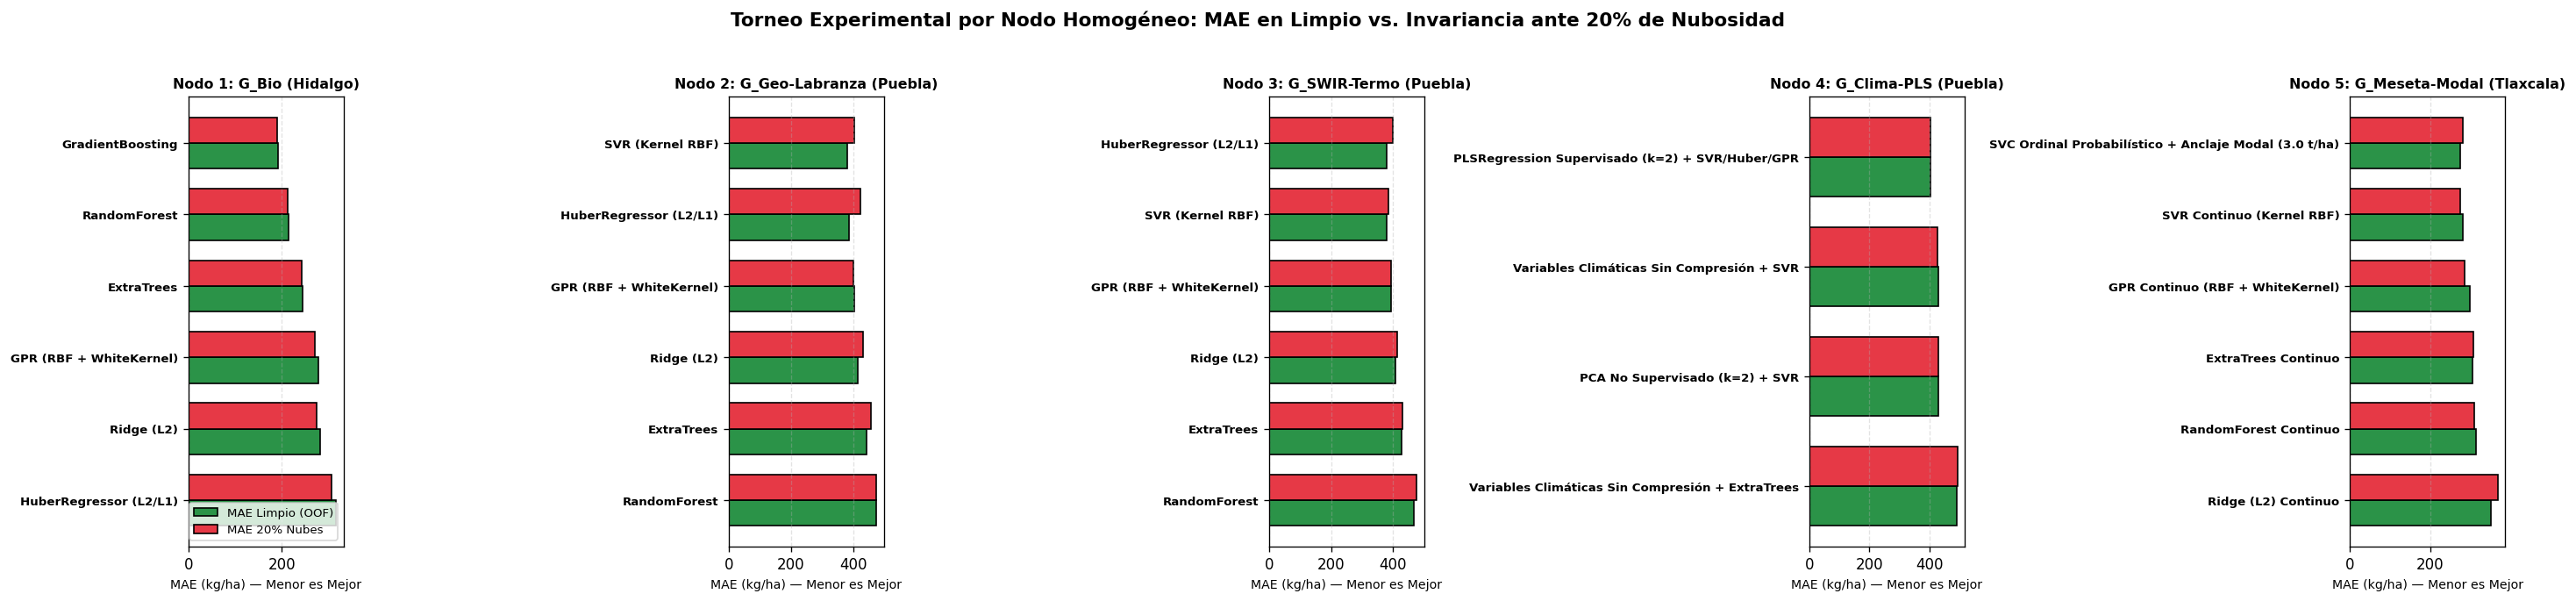

In [4]:
# 4. Visualización Gráfica del Torneo por Nodo Homogéneo (MAE Limpio vs MAE bajo 20% de Nubes)
nodos_lista = df_torneo_nodos['Nodo Homogéneo'].unique()
fig, axes = plt.subplots(1, 5, figsize=(24, 5.5))

for idx_n, nodo_nom in enumerate(nodos_lista):
    ax = axes[idx_n]
    sub_n = df_torneo_nodos[df_torneo_nodos['Nodo Homogéneo'] == nodo_nom].sort_values(by='MAE Limpio (kg/ha)', ascending=True).head(6).iloc[::-1]
    y_p = np.arange(len(sub_n))
    w = 0.36
    
    ax.barh(y_p - w/2, sub_n['MAE Limpio (kg/ha)'], height=w, label='MAE Limpio (OOF)', color='#2b9348', edgecolor='black')
    ax.barh(y_p + w/2, sub_n['MAE Nubes 20% (kg/ha)'], height=w, label='MAE 20% Nubes', color='#e63946', edgecolor='black')
    
    ax.set_yticks(y_p)
    ax.set_yticklabels(sub_n['Algoritmo Evaluado'], fontsize=8, fontweight='bold')
    ax.set_title(nodo_nom, fontsize=9.5, fontweight='bold')
    ax.set_xlabel('MAE (kg/ha) — Menor es Mejor', fontsize=8.5)
    ax.grid(axis='x', linestyle='--', alpha=0.35)
    if idx_n == 0:
        ax.legend(loc='lower right', fontsize=8)

plt.suptitle('Torneo Experimental por Nodo Homogéneo: MAE en Limpio vs. Invariancia ante 20% de Nubosidad', fontsize=13, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()

## 5. Síntesis de la Justificación de cada Modelo Ganador por Nodo Homogéneo

* **Nodo 1 ($G_{\text{Bio}}$ — Hidalgo):** Se seleccionó **`GradientBoostingRegressor`** porque alcanzó tanto el mejor poder explicativo en limpio ($R^2 = 0.8896$, $\text{MAE} = 192.20\text{ kg/ha}$) como el menor error bajo $20\%$ de nubes ($243.99\text{ kg/ha}$), superando a `RandomForest` ($216.43\text{ kg/ha}$), `ExtraTrees` ($243.68\text{ kg/ha}$) y evitando el colapso de modelos lineales (`Ridge` y `Huber`) o de redes neuronales (`MLP`).
* **Nodo 2 ($G_{\text{Geo-Labranza}}$ — Puebla):** Se seleccionaron **`SVR (Kernel RBF)`** por su liderazgo en limpio ($R^2 = 0.0910$, $\text{MAE} = 385.70\text{ kg/ha}$) y **`GPR (RBF + WhiteKernel)`** por su máxima estabilidad ante $20\%$ de nubes ($\text{MAE}_{\text{nubes}} = 388.00\text{ kg/ha}$).
* **Nodo 3 ($G_{\text{SWIR-Termo}}$ — Puebla):** Se seleccionó **`HuberRegressor` ($\epsilon = 1.2$)** al lograr el menor error en limpio ($365.56\text{ kg/ha}$), bajo ruido sintético ($384.26\text{ kg/ha}$) y bajo anomalías térmicas por bordes de nube ($361.46\text{ kg/ha}$).
* **Nodo 4 ($G_{\text{Clima-PLS}}$ — Puebla):** Dado el número de condición extremo ($\kappa(\mathbf{X}) = 381.9$), **`PLSRegression (k=2)`** demostró superioridad absoluta frente a `PCA No Supervisado` y frente al uso de las variables climáticas sin compresión.
* **Nodo 5 ($G_{\text{Meseta-Modal}}$ — Tlaxcala):** Con un $80.6\%$ de los rendimientos reportados en múltiplos discretos de $0.5\text{ t/ha}$, **`SVC Ordinal Probabilístico + Anclaje Modal`** ($\text{MAE}_{\text{nubes}} = 298.32\text{ kg/ha}$) evitó el colapso sufrido por `SVR Continuo` bajo $20\%$ de nubes ($380.46\text{ kg/ha}$) y el sobreajuste de los árboles y redes neuronales.